In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

con = sqlite3.connect("store_lab3.db")
cur = con.cursor()

cur.execute("DROP TABLE IF EXISTS customers;")

cur.execute("""
CREATE TABLE customers (
    id INTEGER PRIMARY KEY,
    name TEXT NOT NULL,
    city TEXT NOT NULL,
    total_purchases REAL NOT NULL
);
""")

cur.execute("""
INSERT INTO customers (id, name, city, total_purchases) VALUES
(1, 'Alex Rivera', 'Los Angeles', 249.50),
(2, 'Jordan Lee', 'Culver City', 120.00),
(3, 'Taylor Swift', 'Santa Monica', 580.25),
(4, 'Morgan Vance', 'Inglewood', 89.99),
(5, 'Casey Zhang', 'Torrance', 310.75),
(6, 'Samira Patel', 'Venice', 45.50),
(7, 'Chris Evans', 'Los Angeles', 199.00),
(8, 'Devon Smith', 'Santa Monica', 412.10);
""")
con.commit()

print("Table rebuilt successfully.")

Table rebuilt successfully.


In [2]:
query_where = """
SELECT * FROM customers
WHERE total_purchases > 150;
"""
print("--- Filtered Query (Purchases > $150) ---")
print(pd.read_sql(query_where, con))

--- Filtered Query (Purchases > $150) ---
   id          name          city  total_purchases
0   1   Alex Rivera   Los Angeles           249.50
1   3  Taylor Swift  Santa Monica           580.25
2   5   Casey Zhang      Torrance           310.75
3   7   Chris Evans   Los Angeles           199.00
4   8   Devon Smith  Santa Monica           412.10


In [3]:
query_order = """
SELECT * FROM customers
ORDER BY total_purchases DESC;
"""
print("\n--- Sorted Query (Purchases Descending) ---")
print(pd.read_sql(query_order, con))


--- Sorted Query (Purchases Descending) ---
   id          name          city  total_purchases
0   3  Taylor Swift  Santa Monica           580.25
1   8   Devon Smith  Santa Monica           412.10
2   5   Casey Zhang      Torrance           310.75
3   1   Alex Rivera   Los Angeles           249.50
4   7   Chris Evans   Los Angeles           199.00
5   2    Jordan Lee   Culver City           120.00
6   4  Morgan Vance     Inglewood            89.99
7   6  Samira Patel        Venice            45.50


In [4]:
query_like = """
SELECT * FROM customers
WHERE name LIKE '%an%';
"""
print("\n--- Wildcard Search (Names containing 'an') ---")
df_like = pd.read_sql(query_like, con)
print(df_like)


--- Wildcard Search (Names containing 'an') ---
   id          name         city  total_purchases
0   2    Jordan Lee  Culver City           120.00
1   4  Morgan Vance    Inglewood            89.99
2   5   Casey Zhang     Torrance           310.75
3   7   Chris Evans  Los Angeles           199.00


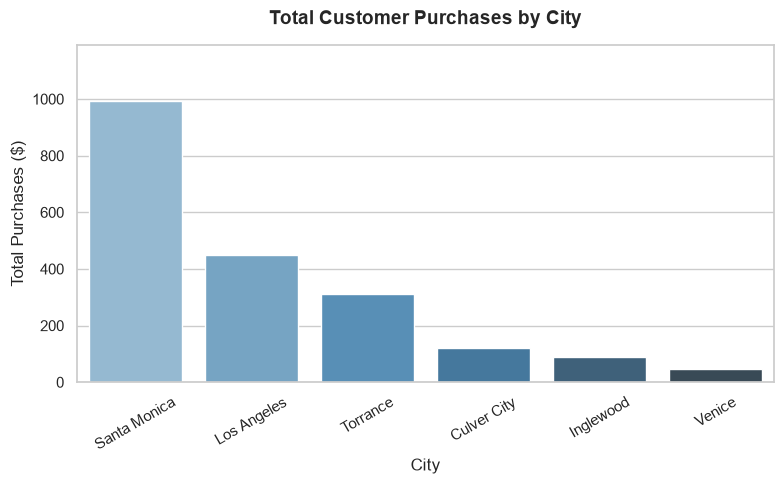

In [5]:

query_chart = """
SELECT city, SUM(total_purchases) AS city_total
FROM customers
GROUP BY city
ORDER BY city_total DESC;
"""
df_city_totals = pd.read_sql(query_chart, con)


plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

sns.barplot(
    data=df_city_totals, x="city", y="city_total", hue="city", palette="Blues_d", legend=False
)

plt.title("Total Customer Purchases by City", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("City", fontsize=12)
plt.ylabel("Total Purchases ($)", fontsize=12)
plt.ylim(0, df_city_totals["city_total"].max() * 1.2)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()